# Face Image Gender Classification

This notebook trains a binary image classifier from `gender_dataset_face/man` and `gender_dataset_face/woman`. It resizes each face, converts it to grayscale, extracts HOG features, evaluates a stratified holdout, then trains and exports a model using all readable images.

**Interpretation note:** the output predicts the dataset's binary folder label (man/woman); it cannot determine a person's gender identity. Do not use this experimental model to make decisions about people.

Keep this notebook beside the `gender_dataset_face` directory, or set `DATASET_DIR` below to its location. Run the cells from top to bottom. 

In [1]:
from pathlib import Path
import cv2
import joblib
import numpy as np
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
import matplotlib.pyplot as plt

RANDOM_STATE = 42
IMAGE_SIZE = (64, 64)
CLASS_NAMES = ["man", "woman"]
SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Set this explicitly if your dataset is stored elsewhere.
DATASET_DIR = Path.cwd() / "gender_dataset_face"
if not DATASET_DIR.is_dir():
    candidates = [Path.cwd().parent / "gender_dataset_face", Path(__file__).resolve().parent / "gender_dataset_face"] if "__file__" in globals() else [Path.cwd().parent / "gender_dataset_face"]
    DATASET_DIR = next((path for path in candidates if path.is_dir()), DATASET_DIR)
if not DATASET_DIR.is_dir():
    raise FileNotFoundError(f"Dataset directory not found: {DATASET_DIR}. Set DATASET_DIR to the dataset path.")

print(f"Dataset: {DATASET_DIR.resolve()}")

Dataset: D:\AI Engineer\Datamites\Intership Project\AI Engineer\PRAICP-1001-GenderDetc\gender_dataset_face


## Load and preprocess images

The notebook ignores metadata files and any unreadable image. HOG (Histogram of Oriented Gradients) converts each resized face into a fixed-length feature vector for the SVM classifier.

In [2]:
hog = cv2.HOGDescriptor(
    _winSize=IMAGE_SIZE,
    _blockSize=(16, 16),
    _blockStride=(8, 8),
    _cellSize=(8, 8),
    _nbins=9,
)

def image_to_hog(image_path, descriptor=hog, image_size=IMAGE_SIZE):
    image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Could not read image: {image_path}")
    image = cv2.resize(image, image_size, interpolation=cv2.INTER_AREA)
    return descriptor.compute(image).ravel().astype(np.float32)

feature_rows = []
labels = []
image_paths = []
skipped = []

for label, class_name in enumerate(CLASS_NAMES):
    class_dir = DATASET_DIR / class_name
    if not class_dir.is_dir():
        raise FileNotFoundError(f"Expected class directory: {class_dir}")
    for path in sorted(class_dir.iterdir()):
        if not path.is_file() or path.suffix.lower() not in SUPPORTED_EXTENSIONS:
            continue
        try:
            feature_rows.append(image_to_hog(path))
            labels.append(label)
            image_paths.append(path)
        except (ValueError, cv2.error) as error:
            skipped.append((path, str(error)))

X = np.asarray(feature_rows, dtype=np.float32)
y = np.asarray(labels, dtype=np.int64)
if len(X) == 0:
    raise ValueError("No readable images were found. Check the dataset path and file formats.")
print(f"Loaded {len(X)} images; feature shape: {X.shape}")
print({name: int(np.sum(y == index)) for index, name in enumerate(CLASS_NAMES)})
print(f"Skipped unreadable images: {len(skipped)}")

Loaded 2307 images; feature shape: (2307, 1764)
{'man': 1173, 'woman': 1134}
Skipped unreadable images: 0


## Train and evaluate

The stratified 80/20 split preserves the class balance. The test split is kept separate from fitting this evaluation model.

Holdout accuracy: 0.9286
              precision    recall  f1-score   support

         man       0.91      0.95      0.93       235
       woman       0.95      0.90      0.93       227

    accuracy                           0.93       462
   macro avg       0.93      0.93      0.93       462
weighted avg       0.93      0.93      0.93       462



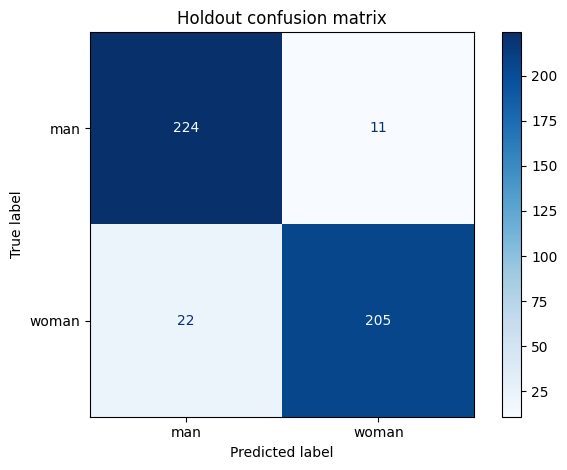

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
evaluation_model = SVC(C=10, kernel="rbf", gamma="scale", class_weight="balanced", probability=True)
evaluation_model.fit(X_train, y_train)
y_pred = evaluation_model.predict(X_test)

print(f"Holdout accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=CLASS_NAMES, cmap="Blues")
plt.title("Holdout confusion matrix")
plt.tight_layout()
plt.show()

## Train final model and save

After reporting the holdout metric, fit the deliverable classifier on all readable images. The artifact includes its classifier and preprocessing metadata.

In [4]:
final_model = SVC(C=10, kernel="rbf", gamma="scale", class_weight="balanced", probability=True)
final_model.fit(X, y)

MODEL_PATH = Path.cwd() / "gender_classifier.joblib"
model_bundle = {
    "model": final_model,
    "class_names": CLASS_NAMES,
    "image_size": IMAGE_SIZE,
    "hog_parameters": {
        "block_size": (16, 16),
        "block_stride": (8, 8),
        "cell_size": (8, 8),
        "bins": 9,
    },
    "training_images": len(X),
    "holdout_accuracy": float(accuracy_score(y_test, y_pred)),
    "sklearn_version": __import__("sklearn").__version__,
}
joblib.dump(model_bundle, MODEL_PATH)
print(f"Saved model: {MODEL_PATH.resolve()}")
print(f"Model size: {MODEL_PATH.stat().st_size / (1024 * 1024):.2f} MB")

Saved model: D:\AI Engineer\Datamites\Intership Project\AI Engineer\PRAICP-1001-GenderDetc\gender_classifier.joblib
Model size: 14.93 MB


## Predict one image

The probability scores are model confidence estimates, not calibrated measures of certainty.

Predicted label: man
man: 99.87%
woman: 0.13%


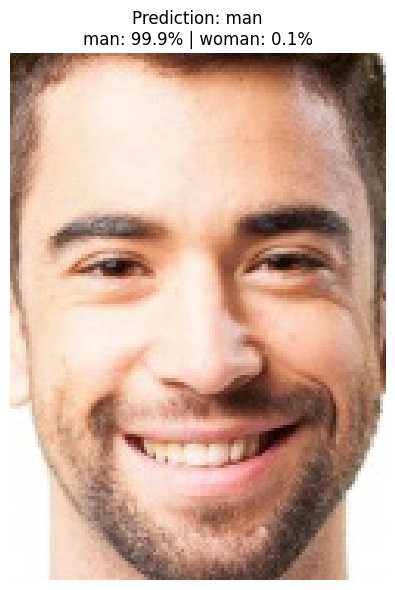

In [5]:
def predict_image(image_path, bundle=None):
    """Predict a folder label for one face image using the saved model bundle."""
    if bundle is None:
        bundle = joblib.load(MODEL_PATH)
    image_size = tuple(bundle["image_size"])
    params = bundle["hog_parameters"]
    descriptor = cv2.HOGDescriptor(
        _winSize=image_size,
        _blockSize=tuple(params["block_size"]),
        _blockStride=tuple(params["block_stride"]),
        _cellSize=tuple(params["cell_size"]),
        _nbins=params["bins"],
    )
    features = image_to_hog(image_path, descriptor, image_size)
    model = bundle["model"]
    probabilities = model.predict_proba(features.reshape(1, -1))[0] if hasattr(model, "predict_proba") else None
    prediction = int(model.predict(features.reshape(1, -1))[0])
    result = {"label": bundle["class_names"][prediction]}
    if probabilities is not None:
        result["scores"] = {name: float(score) for name, score in zip(bundle["class_names"], probabilities)}
    return result

image_path = Path(r"D:\AI Engineer\Datamites\Intership Project\AI Engineer\PRAICP-1001-GenderDetc\gender_dataset_face\man\face_0.jpg")
prediction = predict_image(image_path)
image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError(f"Could not display image: {image_path}")

print(f"Predicted label: {prediction['label']}")
for class_name, probability in prediction["scores"].items():
    print(f"{class_name}: {probability:.2%}")

plt.figure(figsize=(5, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Prediction: " + prediction["label"] + "\n" + " | ".join(
    f"{name}: {score:.1%}" for name, score in prediction["scores"].items()
))
plt.axis("off")
plt.tight_layout()
plt.show()

# Final Project Report: Face Image Gender Classification

## Summary
The HOG + RBF-SVC model was trained on **2,307 readable face images** (1,173 labeled `man`, 1,134 labeled `woman`). On a stratified 80/20 holdout set of 462 images, it achieved **92.86% accuracy**. The final model artifact was then trained on all readable images.

## Approach
1. Load face images from the `man` and `woman` class folders; ignore files that are not supported image types.
2. Convert images to grayscale and resize to 64 x 64 pixels to handle different source image dimensions consistently.
3. Extract Histogram of Oriented Gradients (HOG) features and classify them with an RBF-kernel Support Vector Classifier (SVC), using balanced class weights.
4. Evaluate with a stratified 80/20 train/holdout split. Fit the final model on all readable images and save its preprocessing settings with the classifier.

## Problems encountered and how they were addressed
- **Different image dimensions:** resizing every image to 64 x 64 grayscale gives HOG a consistent input shape.
- **Non-image metadata such as `.DS_Store`:** filtering supported image extensions prevents these files from being mistaken for training data.
- **Slightly different class counts:** stratified splitting preserves class proportions, and balanced class weights account for the difference during fitting.
- **Repeatable inference:** the saved `gender_classifier.joblib` bundle contains the classifier, class names, image size, and HOG parameters.

## Evaluation metrics — stratified holdout
| Label | Precision | Recall | F1-score | Support |
|:--|--:|--:|--:|--:|
| man | 91% | 95% | 93% | 235 |
| woman | 95% | 90% | 93% | 227 |
| Overall accuracy | — | — | 92.86% | 462 |

Confusion matrix (rows are actual labels; columns are predicted labels; order: man, woman):

| Actual \\ Predicted | man | woman |
|:--|--:|--:|
| man | 224 | 11 |
| woman | 22 | 205 |

## Limitations
- The model predicts only the dataset's binary folder labels; these predictions do not determine a person's gender identity and cannot represent labels outside `man`/`woman`.
- The dataset may not represent other populations, image conditions, or camera setups. Holdout performance is not a guarantee of real-world performance.
- The split is by image rather than by person. If the same identity appears in both partitions, the holdout score may be optimistic.
- HOG and this traditional classifier may be less robust to pose, lighting, occlusion, image quality, and backgrounds. Predicted class scores are estimates, not calibrated certainty.
- The model expects a face image; it does not detect or crop faces from full-scene photographs.

**Responsible use:** this project is intended for educational dataset evaluation, not consequential decisions about people.